In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_excel("DecodeLabs_Cleaned_Dataset.xlsx")

In [ ]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [ ]:
df.shape

(1200, 14)

In [ ]:
df.describe()

,Date,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200,1200.000000,1200.000000,1200.000000,1200.000000
mean,2024-03-22 16:58:48,2.945833,356.412750,5.485000,1053.968300
min,2023-01-01 00:00:00,1.000000,11.390000,1.000000,11.390000
25%,2023-08-03 18:00:00,2.000000,186.062500,4.000000,410.520000
50%,2024-03-23 00:00:00,3.000000,364.210000,5.000000,823.615000
75%,2024-11-08 12:00:00,4.000000,521.570000,7.000000,1578.475000
max,2025-06-30 00:00:00,5.000000,699.930000,10.000000,3456.400000
std,NaN,1.407557,197.177146,2.281983,819.856558


In [ ]:
df.describe(include='object')

,OrderID,CustomerID,Product,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,CouponCode,ReferralSource
count,1200,1200,1200,1200,1200,1200,1200,1200,1200
unique,1200,1189,7,655,5,5,1200,4,5
top,ORD200000,C46651,Printer,533 Main St,Online,Cancelled,TRK37947903,FREESHIP,Instagram
freq,1,2,181,8,258,250,1,313,259


In [ ]:
df["OrderStatus"].value_counts()

,count
OrderStatus,
Cancelled,250
Returned,247
Pending,237
Shipped,235
Delivered,231


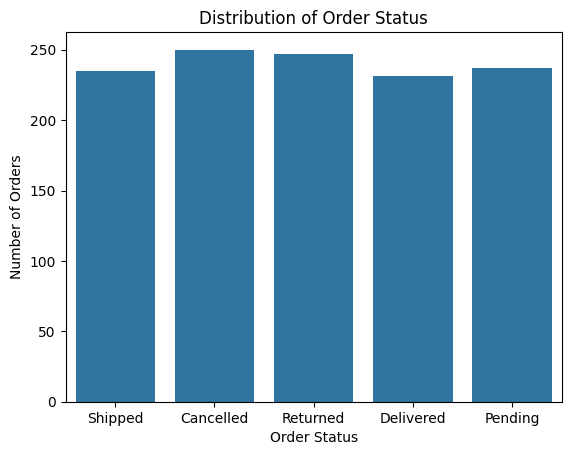

In [ ]:
sns.countplot(data=df, x="OrderStatus")

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.show()

In [ ]:
df["Quantity"].value_counts().sort_index()

,count
Quantity,
1,255
2,240
3,237
4,251
5,217


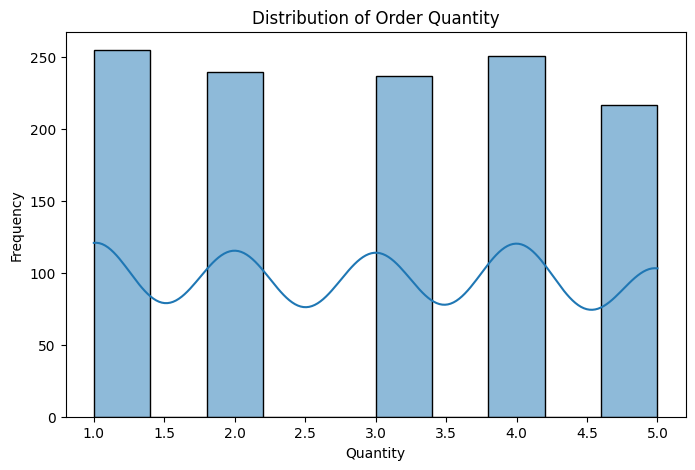

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Quantity", bins=10, kde=True)

plt.title("Distribution of Order Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.show()

In [ ]:
df["UnitPrice"].describe()

,UnitPrice
count,1200.000000
mean,356.412750
std,197.177146
min,11.390000
25%,186.062500
50%,364.210000
75%,521.570000
max,699.930000


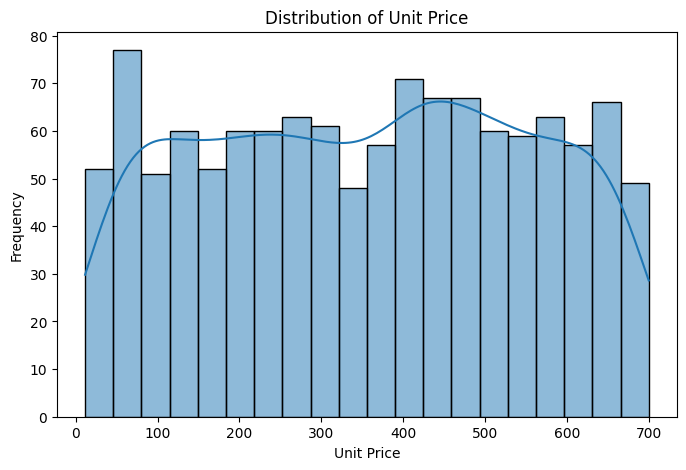

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="UnitPrice", bins=20, kde=True)

plt.title("Distribution of Unit Price")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")

plt.show()

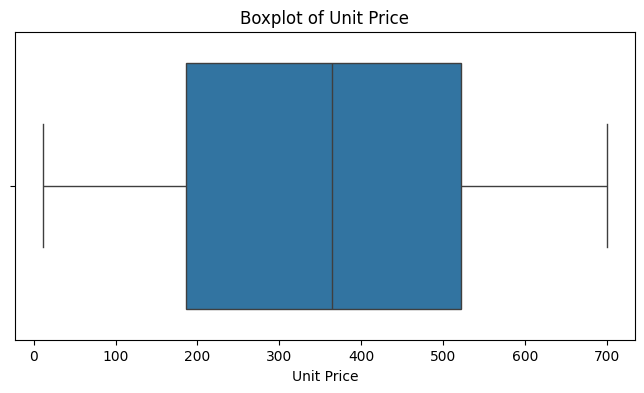

In [ ]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["UnitPrice"])

plt.title("Boxplot of Unit Price")
plt.xlabel("Unit Price")

plt.show()

In [ ]:
df["TotalPrice"].describe()

,TotalPrice
count,1200.000000
mean,1053.968300
std,819.856558
min,11.390000
25%,410.520000
50%,823.615000
75%,1578.475000
max,3456.400000


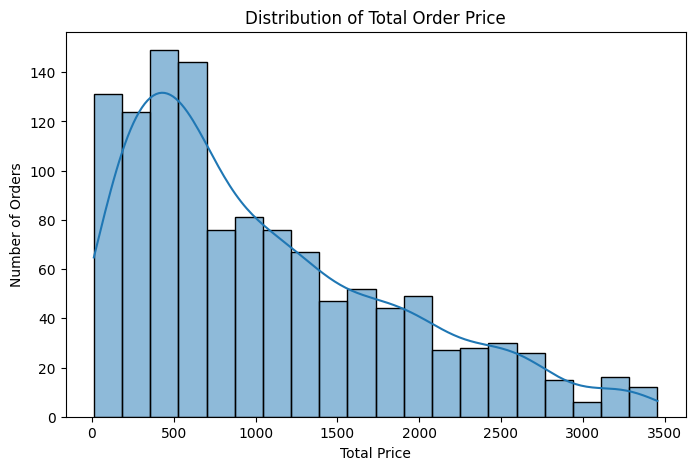

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="TotalPrice", bins=20, kde=True)

plt.title("Distribution of Total Order Price")
plt.xlabel("Total Price")
plt.ylabel("Number of Orders")

plt.show()

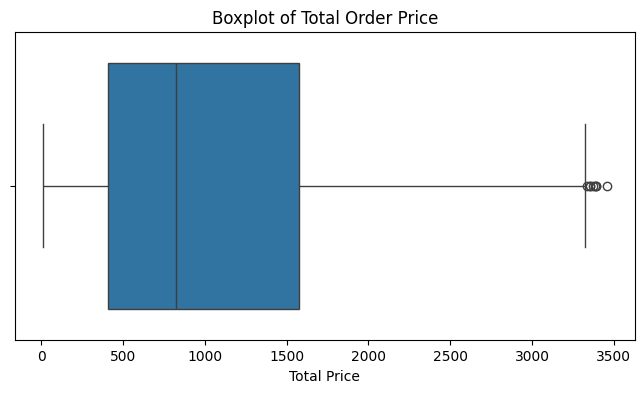

In [ ]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["TotalPrice"])

plt.title("Boxplot of Total Order Price")
plt.xlabel("Total Price")

plt.show()

In [ ]:
df["PaymentMethod"].value_counts()

,count
PaymentMethod,
Online,258
Cash,246
Credit Card,234
Debit Card,232
Gift Card,230


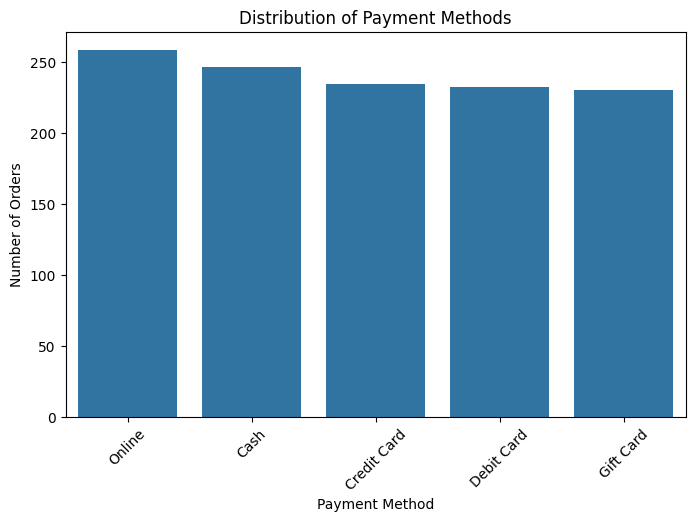

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="PaymentMethod",
              order=df["PaymentMethod"].value_counts().index)

plt.title("Distribution of Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

In [ ]:
df["Product"].value_counts()

,count
Product,
Printer,181
Tablet,179
Chair,178
Laptop,173
Desk,170
Monitor,163
Phone,156


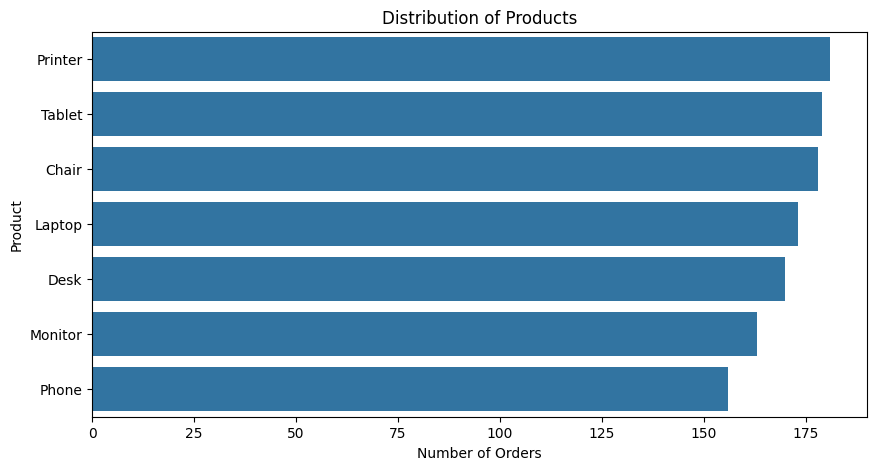

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, y="Product",
              order=df["Product"].value_counts().index)

plt.title("Distribution of Products")
plt.xlabel("Number of Orders")
plt.ylabel("Product")

plt.show()

In [ ]:
df["ReferralSource"].value_counts()

,count
ReferralSource,
Instagram,259
Email,250
Google,241
Facebook,228
Referral,222


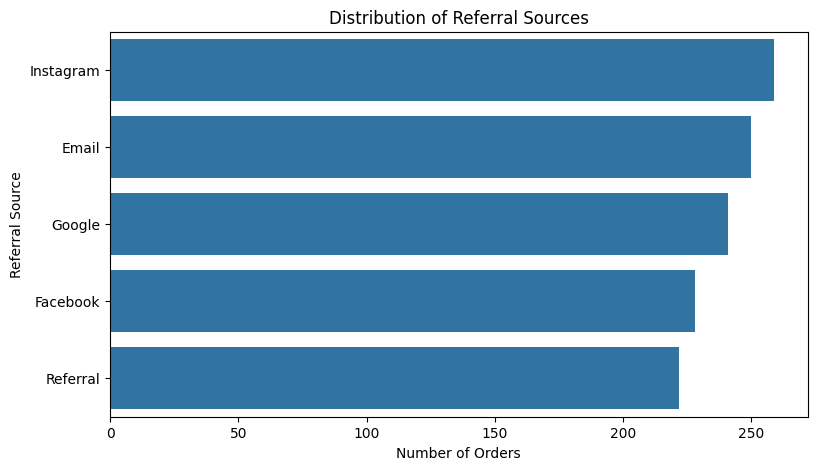

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, y="ReferralSource",
              order=df["ReferralSource"].value_counts().index)

plt.title("Distribution of Referral Sources")
plt.xlabel("Number of Orders")
plt.ylabel("Referral Source")

plt.show()

In [ ]:
referral_percentage = df["ReferralSource"].value_counts(normalize=True) * 100

print(referral_percentage.round(2))

ReferralSource
Instagram    21.58
Email        20.83
Google       20.08
Facebook     19.00
Referral     18.50
Name: proportion, dtype: float64


In [ ]:
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

In [ ]:
monthly_orders = df.groupby("Month")["OrderID"].count()

print(monthly_orders)

Month
1     106
2     106
3     128
4     113
5     120
6     147
7      87
8      79
9      73
10     78
11     76
12     87
Name: OrderID, dtype: int64


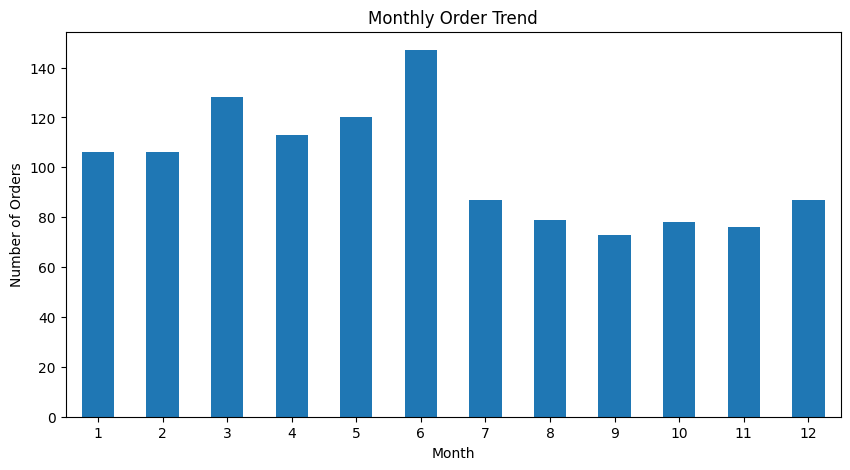

In [ ]:
plt.figure(figsize=(10, 5))

monthly_orders.plot(kind="bar")

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

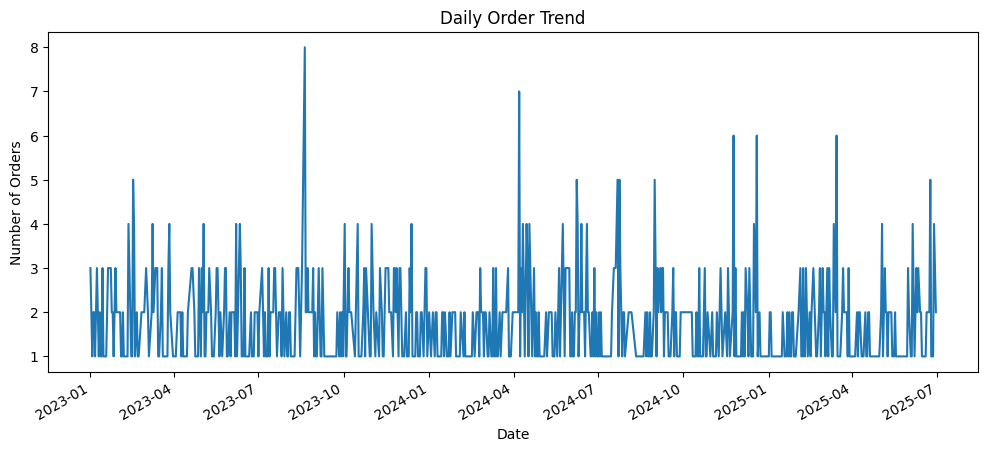

In [ ]:
daily_orders = df.groupby("Date")["OrderID"].count()

plt.figure(figsize=(12, 5))

daily_orders.plot()

plt.title("Daily Order Trend")
plt.xlabel("Date")
plt.ylabel("Number of Orders")

plt.show()

In [ ]:
Q1 = df["TotalPrice"].quantile(0.25)
Q3 = df["TotalPrice"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -1341.4125
Upper Limit: 3330.4075


In [ ]:
outliers = df[
    (df["TotalPrice"] < lower_limit) |
    (df["TotalPrice"] > upper_limit)
]

print("Number of outliers:", len(outliers))

Number of outliers: 8


In [ ]:
outliers[["OrderID", "Product", "Quantity", "UnitPrice", "TotalPrice"]]

,OrderID,Product,Quantity,UnitPrice,TotalPrice
107,ORD200107,Printer,5,670.75,3353.75
326,ORD200326,Laptop,5,670.48,3352.40
328,ORD200328,Tablet,5,674.04,3370.20
469,ORD200469,Chair,5,676.98,3384.90
632,ORD200632,Laptop,5,678.16,3390.80
789,ORD200789,Tablet,5,691.28,3456.40
1065,ORD201065,Printer,5,666.80,3334.00
1122,ORD201122,Monitor,5,678.19,3390.95


In [ ]:
correlation = df[[
    "Quantity",
    "UnitPrice",
    "ItemsInCart",
    "TotalPrice"
]].corr()

print(correlation)

             Quantity  UnitPrice  ItemsInCart  TotalPrice
Quantity     1.000000   0.014553     0.650061    0.615251
UnitPrice    0.014553   1.000000     0.000602    0.717081
ItemsInCart  0.650061   0.000602     1.000000    0.392540
TotalPrice   0.615251   0.717081     0.392540    1.000000


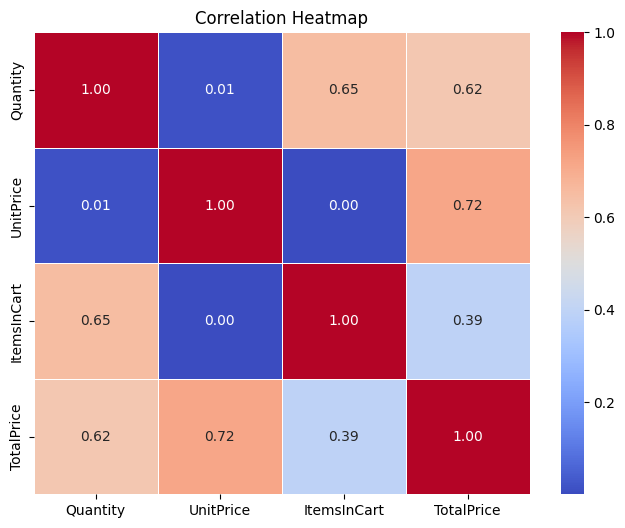

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True, cmap="coolwarm",
            linewidths=0.5, fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
print("Total Orders:", df["OrderID"].nunique())

print("Average Quantity:", round(df["Quantity"].mean(), 2))

print("Average Unit Price:", round(df["UnitPrice"].mean(), 2))

print("Average Order Value:", round(df["TotalPrice"].mean(), 2))

print("Most Common Payment Method:",
      df["PaymentMethod"].mode()[0])

print("Most Ordered Product:",
      df["Product"].mode()[0])

print("Most Common Referral Source:",
      df["ReferralSource"].mode()[0])

print("Most Common Order Status:",
      df["OrderStatus"].mode()[0])

Total Orders: 1200
Average Quantity: 2.95
Average Unit Price: 356.41
Average Order Value: 1053.97
Most Common Payment Method: Online
Most Ordered Product: Printer
Most Common Referral Source: Instagram
Most Common Order Status: Cancelled
